In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Works whether Jupyter was started in the project root or in notebooks/
project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(project_root / "src"))

from extract import RAW_FILES, load_all

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Extraction: all nine raw CSV files are loaded exactly as stored.
tables = load_all()

customers = tables["customers"]
geolocation = tables["geolocation"]
order_items = tables["order_items"]
payments = tables["payments"]
reviews = tables["reviews"]
orders = tables["orders"]
products = tables["products"]
sellers = tables["sellers"]
category_translation = tables["category_translation"]

print("Loaded", len(tables), "tables from", project_root / "data" / "raw")

Loaded 9 tables from c:\Users\NIC\data\raw


## B. Dataset inventory

First, the size of every file. Row counts here are for the full files, nothing is sampled. All nine files together use roughly 320 MB in memory (checked below), so loading them all at once is fine.

In [2]:
inventory = pd.DataFrame(
    {
        "file": [RAW_FILES[name] for name in tables],
        "rows": [df.shape[0] for df in tables.values()],
        "columns": [df.shape[1] for df in tables.values()],
        "memory_mb": [round(df.memory_usage(deep=True).sum() / 1e6, 1) for df in tables.values()],
    },
    index=list(tables),
)
inventory

,file,rows,columns,memory_mb
customers,olist_customers_dataset.csv,99441,5,27.9
geolocation,olist_geolocation_dataset.csv,1000163,5,135.7
order_items,olist_order_items_dataset.csv,112650,7,37.7
payments,olist_order_payments_dataset.csv,103886,5,17.0
reviews,olist_order_reviews_dataset.csv,99224,7,41.0
orders,olist_orders_dataset.csv,99441,8,55.5
products,olist_products_dataset.csv,32951,9,6.6
sellers,olist_sellers_dataset.csv,3095,4,0.6
category_translation,product_category_name_translation.csv,71,2,0.0


Now the columns, data types and a few sample rows of each table. Pandas infers the data types from the CSV, so dates are still plain text (`str`) at this stage.

In [3]:
for name, df in tables.items():
    print("=" * 100)
    print(f"{name}  ({RAW_FILES[name]}):  {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(df.dtypes.to_string())
    display(df.head(3))

customers  (olist_customers_dataset.csv):  99,441 rows x 5 columns
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


geolocation  (olist_geolocation_dataset.csv):  1,000,163 rows x 5 columns
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP


order_items  (olist_order_items_dataset.csv):  112,650 rows x 7 columns
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


sellers  (olist_sellers_dataset.csv):  3,095 rows x 4 columns
seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


category_translation  (product_category_name_translation.csv):  71 rows x 2 columns
product_category_name            str
product_category_name_english    str


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


### What each file appears to represent

This is based on the actual column names above.

| Table | What it appears to represent | Probable grain (one row per ...) |
|---|---|---|
| `customers` | Customer records with city, state and zip prefix. Has both `customer_id` and `customer_unique_id`. | customer_id (to be checked) |
| `geolocation` | Latitude and longitude for Brazilian zip code prefixes. | a coordinate sample for a zip prefix (to be checked) |
| `order_items` | The products inside each order, with seller, price, freight and shipping limit date. | order item (order_id + order_item_id) |
| `payments` | Payment records for each order: type, installments, value. | payment (order_id + payment_sequential) |
| `reviews` | Customer review score, optional comment and review dates. | review (to be checked) |
| `orders` | The central table: status, customer and five order timestamps. | order |
| `products` | Product category (in Portuguese), size and weight, text and photo counts. | product |
| `sellers` | Seller city, state and zip prefix. | seller |
| `category_translation` | Portuguese to English category names. | category |

The three "to be checked" items are tested in section D.

## C. Basic statistical exploration

### Numeric summaries

In [4]:
numeric_columns = {
    "order_items": ["order_item_id", "price", "freight_value"],
    "payments": ["payment_sequential", "payment_installments", "payment_value"],
    "reviews": ["review_score"],
    "products": [
        "product_name_lenght", "product_description_lenght", "product_photos_qty",
        "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm",
    ],
}
for name, columns in numeric_columns.items():
    print(name)
    display(tables[name][columns].describe().T.round(2))

order_items


,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.20,0.71,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.65,183.63,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.99,15.81,0.00,13.08,16.26,21.15,409.68


payments


,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.0,1.09,0.71,1.0,1.00,1.0,1.00,29.00
payment_installments,103886.0,2.85,2.69,0.0,1.00,1.0,4.00,24.00
payment_value,103886.0,154.10,217.49,0.0,56.79,100.0,171.84,13664.08


reviews


,count,mean,std,min,25%,50%,75%,max
review_score,99224.0,4.09,1.35,1.0,4.0,5.0,5.0,5.0


products


,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.48,10.25,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.50,635.12,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.19,1.74,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.47,4282.04,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.82,16.91,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.94,13.64,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.20,12.08,6.0,15.0,20.0,30.0,118.0


### Identifier columns: how many distinct values?

Comparing distinct values with row counts shows where an identifier is unique and where it repeats.

In [5]:
identifier_columns = [
    ("customers", "customer_id"), ("customers", "customer_unique_id"),
    ("orders", "order_id"), ("orders", "customer_id"),
    ("order_items", "order_id"), ("order_items", "product_id"), ("order_items", "seller_id"),
    ("payments", "order_id"),
    ("reviews", "review_id"), ("reviews", "order_id"),
    ("products", "product_id"), ("sellers", "seller_id"),
    ("category_translation", "product_category_name"),
]
rows = []
for table_name, column in identifier_columns:
    series = tables[table_name][column]
    rows.append(
        {"table": table_name, "column": column, "rows": len(series), "distinct": series.nunique(),
         "unique_column": series.is_unique}
    )
pd.DataFrame(rows)

,table,column,rows,distinct,unique_column
0,customers,customer_id,99441,99441,True
1,customers,customer_unique_id,99441,96096,False
2,orders,order_id,99441,99441,True
3,orders,customer_id,99441,99441,True
4,order_items,order_id,112650,98666,False
5,order_items,product_id,112650,32951,False
6,order_items,seller_id,112650,3095,False
7,payments,order_id,103886,99440,False
8,reviews,review_id,99224,98410,False
9,reviews,order_id,99224,98673,False


### Categorical distributions

In [6]:
for table_name, column in [("orders", "order_status"), ("payments", "payment_type"), ("reviews", "review_score")]:
    counts = tables[table_name][column].value_counts()
    summary = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})
    print(f"{table_name}.{column}")
    display(summary.sort_index() if column == "review_score" else summary)

orders.order_status


,count,percent
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


payments.payment_type


,count,percent
payment_type,,
credit_card,76795,73.92
boleto,19784,19.04
voucher,5775,5.56
debit_card,1529,1.47
not_defined,3,0.00


reviews.review_score


,count,percent
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


### Date ranges

Timestamps are converted with `pd.to_datetime` into a separate copy (`orders_dt`, `order_items_dt`, `reviews_dt`). The raw DataFrames stay as they were loaded. `errors="coerce"` turns unparseable text into `NaT`, and section D counts how often that happens.

In [7]:
order_date_columns = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
orders_dt = orders.copy()
for column in order_date_columns:
    orders_dt[column] = pd.to_datetime(orders_dt[column], errors="coerce")

order_items_dt = order_items.copy()
order_items_dt["shipping_limit_date"] = pd.to_datetime(order_items_dt["shipping_limit_date"], errors="coerce")

reviews_dt = reviews.copy()
for column in ["review_creation_date", "review_answer_timestamp"]:
    reviews_dt[column] = pd.to_datetime(reviews_dt[column], errors="coerce")

date_ranges = pd.DataFrame(
    {
        "earliest": [orders_dt[c].min() for c in order_date_columns]
        + [order_items_dt["shipping_limit_date"].min()]
        + [reviews_dt[c].min() for c in ["review_creation_date", "review_answer_timestamp"]],
        "latest": [orders_dt[c].max() for c in order_date_columns]
        + [order_items_dt["shipping_limit_date"].max()]
        + [reviews_dt[c].max() for c in ["review_creation_date", "review_answer_timestamp"]],
    },
    index=order_date_columns + ["shipping_limit_date", "review_creation_date", "review_answer_timestamp"],
)
date_ranges

,earliest,latest
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00
shipping_limit_date,2016-09-19 00:15:34,2020-04-09 22:35:08
review_creation_date,2016-10-02 00:00:00,2018-08-31 00:00:00
review_answer_timestamp,2016-10-07 18:32:28,2018-10-29 12:27:35


## D. Initial data-quality audit

Each check below only reads the data. Nothing is dropped or corrected. At the end of this section I separate problems that are **confirmed** from observations that **need more investigation** in Part 2.

### D1. Missing values

In [8]:
for name, df in tables.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    print(name)
    if missing.empty:
        print("  no missing values")
    else:
        display(pd.DataFrame({"missing": missing, "missing_pct": (missing / len(df) * 100).round(2)}))

customers
  no missing values
geolocation
  no missing values
order_items
  no missing values
payments
  no missing values
reviews


,missing,missing_pct
review_comment_title,87656,88.34
review_comment_message,58247,58.70


orders


,missing,missing_pct
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98


products


,missing,missing_pct
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


sellers
  no missing values
category_translation
  no missing values


Missing timestamps in `orders` may be normal for orders that were never delivered, so they are compared with the order status. Missing product categories may also have a simple explanation.

In [9]:
print("Orders with a missing timestamp, by order status")
missing_by_status = pd.DataFrame(
    {c: orders[orders[c].isna()]["order_status"].value_counts() for c in
     ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]}
).fillna(0).astype(int)
display(missing_by_status)

delivered = orders["order_status"] == "delivered"
print("Delivered orders with no customer delivery date:", (delivered & orders["order_delivered_customer_date"].isna()).sum())
print("Non-delivered orders that HAVE a customer delivery date:", (~delivered & orders["order_delivered_customer_date"].notna()).sum())
print()
print("Review comments: message present =", reviews["review_comment_message"].notna().sum(),
      "| title present =", reviews["review_comment_title"].notna().sum(), "of", len(reviews), "reviews")
print("Products with no category:", products["product_category_name"].isna().sum())

Orders with a missing timestamp, by order status


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


Delivered orders with no customer delivery date: 8
Non-delivered orders that HAVE a customer delivery date: 6

Review comments: message present = 40977 | title present = 11568 of 99224 reviews
Products with no category: 610


### D2. Duplicate rows and duplicate identifiers

A full duplicate row is one where every column matches. A duplicate identifier is a key that should be unique but repeats. These are different problems and are checked separately.

In [10]:
print("Fully duplicated rows per table")
display(pd.Series({name: int(df.duplicated().sum()) for name, df in tables.items()}, name="duplicate_rows"))

key_checks = [
    ("customers", ["customer_id"]),
    ("orders", ["order_id"]),
    ("order_items", ["order_id", "order_item_id"]),
    ("payments", ["order_id", "payment_sequential"]),
    ("reviews", ["review_id"]),
    ("reviews", ["review_id", "order_id"]),
    ("products", ["product_id"]),
    ("sellers", ["seller_id"]),
    ("category_translation", ["product_category_name"]),
]
key_results = pd.DataFrame(
    [{"table": t, "key": " + ".join(k), "repeated_rows": int(tables[t].duplicated(k).sum())} for t, k in key_checks]
)
print("Candidate primary keys: rows whose key repeats an earlier row")
display(key_results)

Fully duplicated rows per table


customers                    0
geolocation             261831
order_items                  0
payments                     0
reviews                      0
orders                       0
products                     0
sellers                      0
category_translation         0
Name: duplicate_rows, dtype: int64

Candidate primary keys: rows whose key repeats an earlier row


,table,key,repeated_rows
0,customers,customer_id,0
1,orders,order_id,0
2,order_items,order_id + order_item_id,0
3,payments,order_id + payment_sequential,0
4,reviews,review_id,814
5,reviews,review_id + order_id,0
6,products,product_id,0
7,sellers,seller_id,0
8,category_translation,product_category_name,0


`review_id` repeats even though a review should be one record. Let me look at how it repeats.

In [11]:
repeated_reviews = reviews[reviews["review_id"].duplicated(keep=False)]
orders_per_review_id = repeated_reviews.groupby("review_id")["order_id"].nunique()
print("review_id values that appear more than once:", orders_per_review_id.shape[0])
print("Distinct orders sharing each repeated review_id:")
print(orders_per_review_id.value_counts().to_string())
print("Repeated review_ids with different scores:", int((repeated_reviews.groupby("review_id")["review_score"].nunique() > 1).sum()))
print("Orders with more than one review:", int((reviews["order_id"].value_counts() > 1).sum()))
display(repeated_reviews.sort_values("review_id").head(4)[["review_id", "order_id", "review_score", "review_creation_date"]])

review_id values that appear more than once: 789
Distinct orders sharing each repeated review_id:
order_id
2    764
3     25
Repeated review_ids with different scores: 0
Orders with more than one review: 547


,review_id,order_id,review_score,review_creation_date
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,2018-03-07 00:00:00
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,2018-03-07 00:00:00
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,2017-09-21 00:00:00
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,2017-09-21 00:00:00


### D3. Relationships between tables (candidate foreign keys)

An orphan is a child row whose key has no match in the parent table. The second table shows the cardinality, meaning how many child rows each order has.

In [12]:
relationships = [
    ("orders", "customer_id", "customers", "customer_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"),
    ("reviews", "order_id", "orders", "order_id"),
]
orphans = pd.DataFrame(
    [
        {"child": f"{c}.{cc}", "parent": f"{p}.{pc}",
         "orphan_rows": int((~tables[c][cc].isin(tables[p][pc])).sum())}
        for c, cc, p, pc in relationships
    ]
)
display(orphans)

used_categories = set(products["product_category_name"].dropna())
print("Product categories missing from the translation table:",
      sorted(used_categories - set(category_translation["product_category_name"])))

print()
print("Orders with NO matching rows in:")
for name in ["order_items", "payments", "reviews"]:
    print(f"  {name}: {int((~orders['order_id'].isin(tables[name]['order_id'])).sum())}")
print("Orders with no items, by status:")
print(orders[~orders["order_id"].isin(order_items["order_id"])]["order_status"].value_counts().to_string())

,child,parent,orphan_rows
0,orders.customer_id,customers.customer_id,0
1,order_items.order_id,orders.order_id,0
2,order_items.product_id,products.product_id,0
3,order_items.seller_id,sellers.seller_id,0
4,payments.order_id,orders.order_id,0
5,reviews.order_id,orders.order_id,0


Product categories missing from the translation table: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Orders with NO matching rows in:
  order_items: 775
  payments: 1
  reviews: 768
Orders with no items, by status:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1


In [13]:
print("Rows per order (cardinality)")
cardinality = pd.DataFrame(
    {
        "order_items": order_items.groupby("order_id").size().describe(),
        "payments": payments.groupby("order_id").size().describe(),
        "reviews": reviews.groupby("order_id").size().describe(),
    }
).round(2)
display(cardinality)

print("Orders paid with more than one payment type:",
      int((payments.groupby("order_id")["payment_type"].nunique() > 1).sum()))
print("Rows if order_items is joined straight to payments:",
      len(order_items.merge(payments, on="order_id")), "(order_items alone has", len(order_items), "rows)")

print()
print("Customers: customer_id values =", customers["customer_id"].nunique(),
      "| customer_unique_id values =", customers["customer_unique_id"].nunique())
print("customer_unique_id values linked to more than one customer_id:",
      int((customers["customer_unique_id"].value_counts() > 1).sum()))

Rows per order (cardinality)


,order_items,payments,reviews
count,98666.00,99440.00,98673.00
mean,1.14,1.04,1.01
std,0.54,0.38,0.08
min,1.00,1.00,1.00
25%,1.00,1.00,1.00
50%,1.00,1.00,1.00
75%,1.00,1.00,1.00
max,21.00,29.00,3.00


Orders paid with more than one payment type: 2246
Rows if order_items is joined straight to payments: 117601 (order_items alone has 112650 rows)

Customers: customer_id values = 99441 | customer_unique_id values = 96096
customer_unique_id values linked to more than one customer_id: 2997


The join check above is important for later milestones. Joining items to payments directly produces more rows than there are items, so any revenue sum on that join would be inflated.

Next, a first comparison of what was paid with what the items cost (price plus freight) for each order. This is only a plausibility check, not a final reconciliation.

In [14]:
item_totals = order_items.groupby("order_id").agg(item_price=("price", "sum"), item_freight=("freight_value", "sum"))
item_totals["items_plus_freight"] = item_totals["item_price"] + item_totals["item_freight"]
paid_totals = payments.groupby("order_id")["payment_value"].sum().rename("paid")
comparison = item_totals.join(paid_totals, how="inner")
comparison["difference"] = comparison["paid"] - comparison["items_plus_freight"]

print("Orders compared:", len(comparison))
print("Paid equals items + freight (within 0.01):", int((comparison["difference"].abs() <= 0.01).sum()))
print("Difference larger than 1.00 in either direction:", int((comparison["difference"].abs() > 1).sum()))
print("Overall totals: item price =", round(order_items["price"].sum(), 2),
      "| freight =", round(order_items["freight_value"].sum(), 2),
      "| payment_value =", round(payments["payment_value"].sum(), 2))
display(comparison[comparison["difference"].abs() > 1].sort_values("difference").head(5).round(2))

Orders compared: 98665
Paid equals items + freight (within 0.01): 98284
Difference larger than 1.00 in either direction: 249
Overall totals: item price = 13591643.7 | freight = 2251909.54 | payment_value = 16008872.12


,item_price,item_freight,items_plus_freight,paid,difference
order_id,,,,,
262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,177.74,126.12,-51.62
fd33085945f15975375cd8ec85440511,217.99,16.63,234.62,212.82,-21.80
6e57e23ecac1ae881286657694444267,330.00,20.41,350.41,333.91,-16.50
4154bf1348caac78152fe76e3e9c4af8,149.90,15.36,165.26,150.27,-14.99
6dcf0aeb8b1eb4021c26e1d0e9394979,299.00,34.92,333.92,318.97,-14.95


### D4. Invalid or suspicious numeric values

In [15]:
print("order_items: price <= 0:", int((order_items["price"] <= 0).sum()),
      "| freight_value == 0:", int((order_items["freight_value"] == 0).sum()),
      "| freight_value < 0:", int((order_items["freight_value"] < 0).sum()),
      "| freight greater than price:", int((order_items["freight_value"] > order_items["price"]).sum()))
print("payments: payment_value == 0:", int((payments["payment_value"] == 0).sum()),
      "| installments == 0:", int((payments["payment_installments"] == 0).sum()))
print("products: weight == 0:", int((products["product_weight_g"] == 0).sum()))
print()
print("Payment types of the rows with payment_value == 0")
print(payments[payments["payment_value"] == 0]["payment_type"].value_counts().to_string())
print()
print("Review comments that are empty or only spaces:",
      int((reviews["review_comment_message"].dropna().str.strip() == "").sum()))

order_items: price <= 0: 0 | freight_value == 0: 383 | freight_value < 0: 0 | freight greater than price: 4124
payments: payment_value == 0: 9 | installments == 0: 2
products: weight == 0: 4

Payment types of the rows with payment_value == 0
payment_type
voucher        6
not_defined    3

Review comments that are empty or only spaces: 27


### D5. Date parsing and logical order of dates

First, did any non-empty timestamp fail to parse? Then, do the timestamps follow the expected order of purchase, approval, carrier pickup and customer delivery?

In [16]:
parse_failures = {}
for column in order_date_columns:
    parse_failures[f"orders.{column}"] = int((orders_dt[column].isna() & orders[column].notna()).sum())
parse_failures["order_items.shipping_limit_date"] = int(
    (order_items_dt["shipping_limit_date"].isna() & order_items["shipping_limit_date"].notna()).sum())
for column in ["review_creation_date", "review_answer_timestamp"]:
    parse_failures[f"reviews.{column}"] = int((reviews_dt[column].isna() & reviews[column].notna()).sum())
display(pd.Series(parse_failures, name="values_that_failed_to_parse"))

o = orders_dt
logical_checks = {
    "approved before purchase": o["order_approved_at"] < o["order_purchase_timestamp"],
    "carrier pickup before approval": o["order_delivered_carrier_date"] < o["order_approved_at"],
    "carrier pickup before purchase": o["order_delivered_carrier_date"] < o["order_purchase_timestamp"],
    "customer delivery before carrier pickup": o["order_delivered_customer_date"] < o["order_delivered_carrier_date"],
    "customer delivery before purchase": o["order_delivered_customer_date"] < o["order_purchase_timestamp"],
    "estimated delivery before purchase": o["order_estimated_delivery_date"] < o["order_purchase_timestamp"],
}
display(pd.Series({k: int(v.sum()) for k, v in logical_checks.items()}, name="orders_affected"))

review_check = reviews_dt.merge(orders_dt[["order_id", "order_purchase_timestamp"]], on="order_id")
print("Reviews created before the order purchase date:",
      int((review_check["review_creation_date"] < review_check["order_purchase_timestamp"]).sum()))
print("Review answered before it was created:",
      int((reviews_dt["review_answer_timestamp"] < reviews_dt["review_creation_date"]).sum()))
print("Shipping limit dates later than the last order purchase date:",
      int((order_items_dt["shipping_limit_date"] > orders_dt["order_purchase_timestamp"].max()).sum()))

orders.order_purchase_timestamp         0
orders.order_approved_at                0
orders.order_delivered_carrier_date     0
orders.order_delivered_customer_date    0
orders.order_estimated_delivery_date    0
order_items.shipping_limit_date         0
reviews.review_creation_date            0
reviews.review_answer_timestamp         0
Name: values_that_failed_to_parse, dtype: int64

approved before purchase                      0
carrier pickup before approval             1359
carrier pickup before purchase              166
customer delivery before carrier pickup      23
customer delivery before purchase             0
estimated delivery before purchase            0
Name: orders_affected, dtype: int64

Reviews created before the order purchase date: 74
Review answered before it was created: 0
Shipping limit dates later than the last order purchase date: 4


### D6. Text formatting and category consistency

In [17]:
def text_issues(series):
    # Counts of simple formatting problems in a text column.
    return {
        "distinct": series.nunique(),
        "extra_spaces": int((series != series.str.strip()).sum()),
        "not_lowercase": int((series != series.str.lower()).sum()),
        "has_non_ascii": int(series.map(lambda text: any(ord(ch) > 127 for ch in text)).sum()),
        "has_digits": int(series.str.contains(r"\d").sum()),
        "has_slash_or_comma": int(series.str.contains(r"[/,]").sum()),
    }

text_columns = [
    ("customers", "customer_city"), ("sellers", "seller_city"), ("geolocation", "geolocation_city"),
    ("products", "product_category_name"),
]
display(pd.DataFrame({f"{t}.{c}": text_issues(tables[t][c].dropna()) for t, c in text_columns}).T)

print("Examples of seller_city values that look inconsistent:")
print(sellers[~sellers["seller_city"].str.match(r"^[a-z \-]+$")]["seller_city"].head(8).tolist())

print()
print("Distinct state codes: customers =", customers["customer_state"].nunique(),
      "| sellers =", sellers["seller_state"].nunique(), "| geolocation =", geolocation["geolocation_state"].nunique())
print("Longest state code length:", max(df[c].str.len().max() for df, c in
      [(customers, "customer_state"), (sellers, "seller_state"), (geolocation, "geolocation_state")]))

print()
print("Zip prefixes stored with only 4 digits (leading zero probably lost):")
for df, c in [(customers, "customer_zip_code_prefix"), (sellers, "seller_zip_code_prefix"), (geolocation, "geolocation_zip_code_prefix")]:
    print(f"  {c}: {int((df[c] < 10000).sum())} of {len(df)}")

,distinct,extra_spaces,not_lowercase,has_non_ascii,has_digits,has_slash_or_comma
customers.customer_city,4119,0,0,0,1,0
sellers.seller_city,611,0,0,3,1,17
geolocation.geolocation_city,8011,1,0,73442,11,2
products.product_category_name,73,0,0,0,95,0


Examples of seller_city values that look inconsistent:
['auriflama/sp', 'sao paulo / sao paulo', 'são paulo', 'santa barbara d´oeste', '04482255', 'novo hamburgo, rio grande do sul, brasil', 'cariacica / es', "sao miguel d'oeste"]

Distinct state codes: customers = 27 | sellers = 23 | geolocation = 27
Longest state code length: 2

Zip prefixes stored with only 4 digits (leading zero probably lost):
  customer_zip_code_prefix: 23995 of 99441
  seller_zip_code_prefix: 1027 of 3095
  geolocation_zip_code_prefix: 245733 of 1000163


### D7. Geolocation table

This is the largest file, so it gets its own checks.

In [18]:
print("Rows:", len(geolocation), "| distinct zip prefixes:", geolocation["geolocation_zip_code_prefix"].nunique())
print("Fully duplicated rows:", int(geolocation.duplicated().sum()),
      f"({geolocation.duplicated().mean() * 100:.1f}% of rows)")
print("Rows per zip prefix:")
print(geolocation.groupby("geolocation_zip_code_prefix").size().describe().round(1).to_string())

# Rough bounding box of Brazil: latitude about -34 to 5.3, longitude about -74 to -34.
outside = geolocation[
    (geolocation["geolocation_lat"] > 5.3) | (geolocation["geolocation_lat"] < -34)
    | (geolocation["geolocation_lng"] > -34) | (geolocation["geolocation_lng"] < -74)
]
print("Coordinates outside Brazil's rough bounding box:", len(outside))
print("Customer rows whose zip prefix exists in geolocation:",
      f"{customers['customer_zip_code_prefix'].isin(geolocation['geolocation_zip_code_prefix']).mean() * 100:.2f}%")
print("Seller rows whose zip prefix exists in geolocation:",
      f"{sellers['seller_zip_code_prefix'].isin(geolocation['geolocation_zip_code_prefix']).mean() * 100:.2f}%")

Rows: 1000163 | distinct zip prefixes: 19015
Fully duplicated rows: 261831 (26.2% of rows)
Rows per zip prefix:
count    19015.0
mean        52.6
std         72.1
min          1.0
25%         10.0
50%         29.0
75%         66.5
max       1146.0
Coordinates outside Brazil's rough bounding box: 42
Customer rows whose zip prefix exists in geolocation: 99.72%
Seller rows whose zip prefix exists in geolocation: 99.77%


### D8. Outliers

The IQR rule (values beyond 1.5 times the interquartile range from the quartiles) is used as a rough screen. A value flagged this way is **not** automatically an error. Online shops legitimately sell a few expensive or heavy items, so the question for Part 2 is whether each extreme value is plausible.

In [19]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    spread = q3 - q1
    flagged = int(((series < q1 - 1.5 * spread) | (series > q3 + 1.5 * spread)).sum())
    return {"rows": len(series), "flagged": flagged, "flagged_pct": round(flagged / len(series) * 100, 2),
            "median": series.median(), "p99": series.quantile(0.99), "max": series.max()}

outlier_columns = [
    ("order_items", "price"), ("order_items", "freight_value"),
    ("payments", "payment_value"), ("products", "product_weight_g"),
]
pd.DataFrame({f"{t}.{c}": iqr_outliers(tables[t][c].dropna()) for t, c in outlier_columns}).T.round(2)

,rows,flagged,flagged_pct,median,p99,max
order_items.price,112650.0,8427.0,7.48,74.99,890.00,6735.00
order_items.freight_value,112650.0,12134.0,10.77,16.26,84.52,409.68
payments.payment_value,103886.0,7981.0,7.68,100.00,1039.92,13664.08
products.product_weight_g,32949.0,4551.0,13.81,700.00,22538.00,40425.00


### D9. Candidate primary keys and foreign keys

Based on the checks above:

| Table | Candidate primary key | Candidate foreign keys | Evidence |
|---|---|---|---|
| `customers` | `customer_id` | none | unique per row |
| `orders` | `order_id` | `customer_id` to `customers` | unique per row, no orphan customers |
| `order_items` | (`order_id`, `order_item_id`) | `order_id`, `product_id`, `seller_id` | composite key has no repeats, no orphans |
| `payments` | (`order_id`, `payment_sequential`) | `order_id` | composite key has no repeats, no orphans |
| `reviews` | not settled | `order_id` | `review_id` repeats across orders, so the key needs a decision |
| `products` | `product_id` | `product_category_name` to `category_translation` (partly) | unique per row, two categories are missing from the translation table |
| `sellers` | `seller_id` | none | unique per row |
| `category_translation` | `product_category_name` | none | unique per row |
| `geolocation` | none (zip prefix repeats many times) | none | not unique at any level |

### Confirmed problems and open questions

**Confirmed from the checks above (these need a cleaning decision):**
- `review_id` is not unique: the same `review_id` is attached to several different orders.
- Product category is missing for part of the product table, and two used categories have no English translation.
- Missing order timestamps exist, mostly explained by order status, but a few delivered orders lack carrier or customer delivery dates.
- Some orders have no order items or no payments. Most of them are canceled, unavailable or still in progress.
- `payment_value` of zero exists, together with payment type `not_defined`.
- The geolocation table has a large share of fully duplicated rows and many zip prefixes with several coordinates.
- City names are inconsistent (accents, state codes or extra text inside some values), mostly in sellers and geolocation.
- Zip code prefixes lost their leading zeros in all three tables that carry them.
- Some timestamps are out of logical order (for example carrier pickup before approval).

**Observations that need more investigation in Part 2:**
- Whether orders where paid value differs from items plus freight are real (vouchers, interest on installments) or data errors.
- Whether the IQR outliers in price, freight, payment value and weight are legitimate.
- Whether reviews created before the purchase date are errors or a timezone/recording effect.
- How to treat order timestamps that are logically out of order.
- How to choose between a timestamp comparison and a date comparison for late deliveries (see section E).
- Whether `customer_unique_id` should be used to count real customers instead of `customer_id`.

## E. Initial exploratory questions

These are first looks only. The final, defined analysis happens in Part 2 after cleaning.

### E1. How are orders distributed across their statuses?

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00


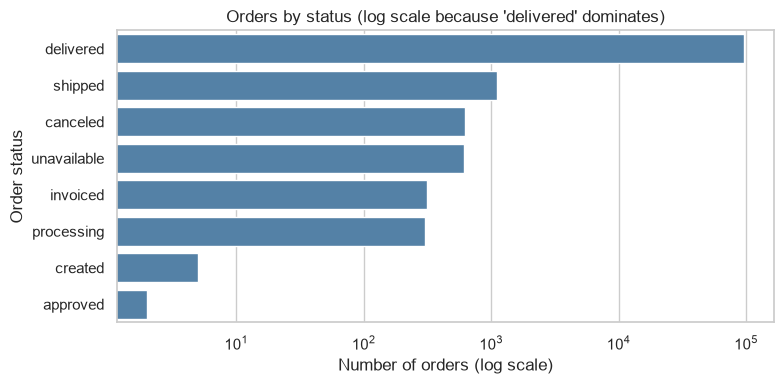

In [20]:
status_counts = orders["order_status"].value_counts()
print((status_counts / status_counts.sum() * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=status_counts.values, y=status_counts.index, color="steelblue", ax=ax)
ax.set_xscale("log")
ax.set_title("Orders by status (log scale because 'delivered' dominates)")
ax.set_xlabel("Number of orders (log scale)")
ax.set_ylabel("Order status")
plt.tight_layout()
plt.show()

### E2. How does order volume change over time?

Orders are counted by purchase month, using all statuses. Months at the very start and end of the data may be incomplete, so the table is printed as well.

order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Freq: M
...
order_purchase_timestamp
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M
Months with at least one order: 25 | first: 2016-09 | last: 2018-10


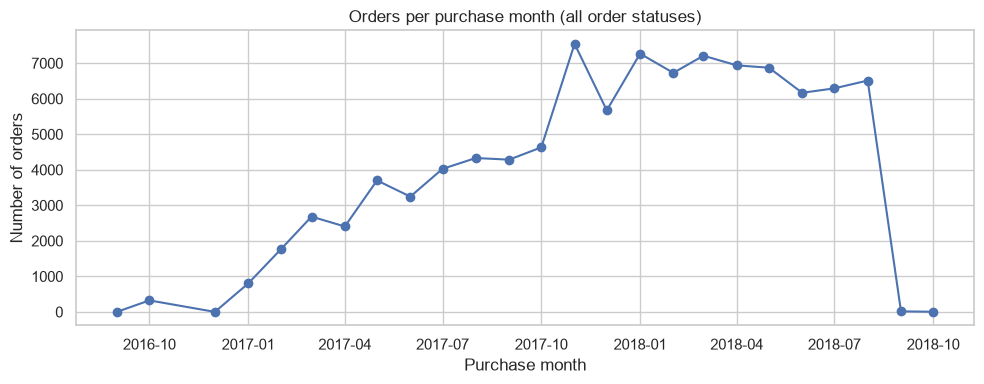

In [21]:
orders_per_month = orders_dt.groupby(orders_dt["order_purchase_timestamp"].dt.to_period("M")).size()
print(orders_per_month.head(4).to_string())
print("...")
print(orders_per_month.tail(4).to_string())
print("Months with at least one order:", len(orders_per_month),
      "| first:", orders_per_month.index.min(), "| last:", orders_per_month.index.max())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(orders_per_month.index.to_timestamp(), orders_per_month.values, marker="o")
ax.set_title("Orders per purchase month (all order statuses)")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

### E3. Which payment methods are recorded most often?

This counts payment **records**, not orders, because an order can have several payment rows.

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00


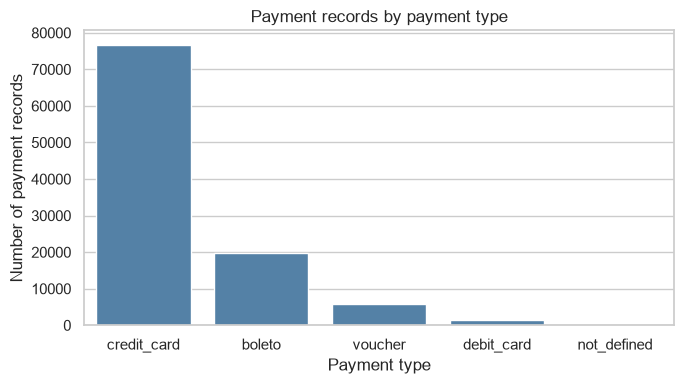

In [22]:
payment_counts = payments["payment_type"].value_counts()
print((payment_counts / payment_counts.sum() * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=payment_counts.index, y=payment_counts.values, color="steelblue", ax=ax)
ax.set_title("Payment records by payment type")
ax.set_xlabel("Payment type")
ax.set_ylabel("Number of payment records")
plt.tight_layout()
plt.show()

### E4. How are review scores distributed?

review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Mean score: 4.086


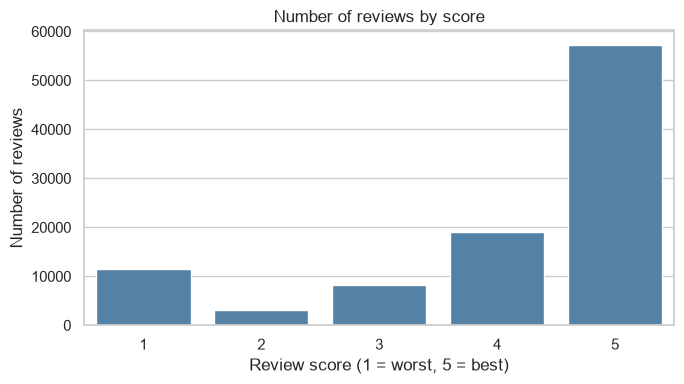

In [23]:
score_counts = reviews["review_score"].value_counts().sort_index()
print((score_counts / score_counts.sum() * 100).round(2).to_string())
print("Mean score:", round(reviews["review_score"].mean(), 3))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=score_counts.index, y=score_counts.values, color="steelblue", ax=ax)
ax.set_title("Number of reviews by score")
ax.set_xlabel("Review score (1 = worst, 5 = best)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

### E5. Which product categories appear most often?

Counted as **order items sold** per category. The English names come from `category_translation`. Both joins are many-to-one (each item has one product, each product has one category), so the item count is not inflated.

Distinct categories among sold items: 74
Items with no category: 1603


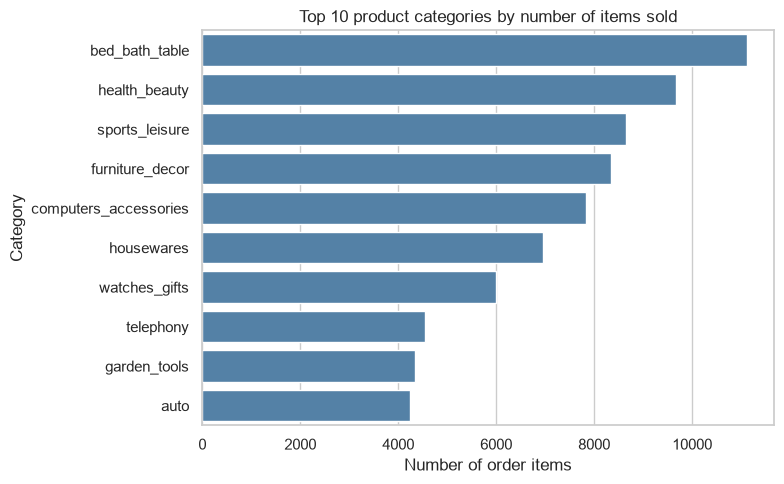

In [24]:
items_with_category = (
    order_items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(category_translation, on="product_category_name", how="left")
)
assert len(items_with_category) == len(order_items)  # no row multiplication

# Two Portuguese categories have no translation, so fall back to the Portuguese name.
items_with_category["category"] = (
    items_with_category["product_category_name_english"]
    .fillna(items_with_category["product_category_name"])
    .fillna("(no category)")
)
top_categories = items_with_category["category"].value_counts().head(10)
print("Distinct categories among sold items:", items_with_category["category"].nunique())
print("Items with no category:", int((items_with_category["category"] == "(no category)").sum()))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top_categories.values, y=top_categories.index, color="steelblue", ax=ax)
ax.set_title("Top 10 product categories by number of items sold")
ax.set_xlabel("Number of order items")
ax.set_ylabel("Category")
plt.tight_layout()
plt.show()

### E6. How do delivery dates compare with the estimated delivery date?

Only orders with status `delivered` **and** a recorded customer delivery date are used. Canceled or unfinished orders have no real delivery, so including them would be meaningless.

The estimated delivery date is always at midnight, while the delivery date has a time of day. That means a package delivered at 10:00 on the estimated day counts as "late" if full timestamps are compared. Both versions are calculated so the difference is visible.

Denominator: delivered orders with a delivery date = 96470
Late by full timestamp: 7826 (8.11%)
Late by calendar date:  6534 (6.77%)
All estimated dates at midnight: True
count    96470.00
mean       -11.18
std         10.18
min       -146.02
25%        -16.24
50%        -11.95
75%         -6.39
max        188.98
Orders outside the plotted range of -60 to +60 days: 118


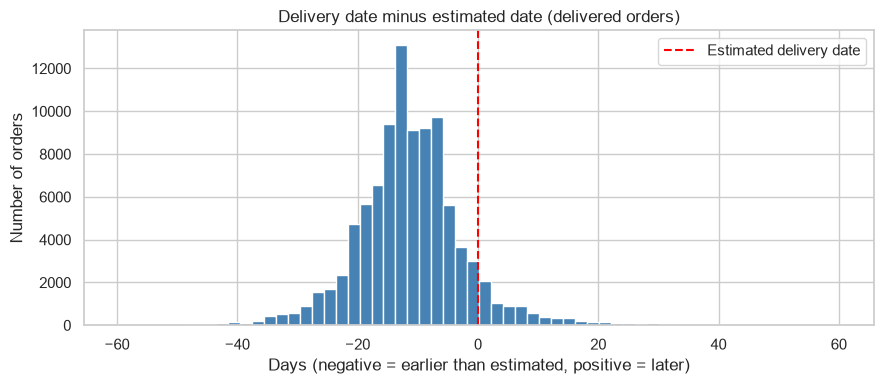

In [25]:
delivered_orders = orders_dt[
    (orders_dt["order_status"] == "delivered") & orders_dt["order_delivered_customer_date"].notna()
].copy()

delivered_orders["days_vs_estimate"] = (
    delivered_orders["order_delivered_customer_date"] - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400
late_by_timestamp = delivered_orders["order_delivered_customer_date"] > delivered_orders["order_estimated_delivery_date"]
late_by_date = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    > delivered_orders["order_estimated_delivery_date"].dt.normalize()
)

print("Denominator: delivered orders with a delivery date =", len(delivered_orders))
print(f"Late by full timestamp: {late_by_timestamp.sum()} ({late_by_timestamp.mean() * 100:.2f}%)")
print(f"Late by calendar date:  {late_by_date.sum()} ({late_by_date.mean() * 100:.2f}%)")
print("All estimated dates at midnight:",
      bool((orders_dt["order_estimated_delivery_date"].dt.time == pd.Timestamp("00:00:00").time()).all()))
print(delivered_orders["days_vs_estimate"].describe().round(2).to_string())

shown = delivered_orders["days_vs_estimate"].between(-60, 60)
print("Orders outside the plotted range of -60 to +60 days:", int((~shown).sum()))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(delivered_orders.loc[shown, "days_vs_estimate"], bins=60, color="steelblue")
ax.axvline(0, color="red", linestyle="--", label="Estimated delivery date")
ax.set_title("Delivery date minus estimated date (delivered orders)")
ax.set_xlabel("Days (negative = earlier than estimated, positive = later)")
ax.set_ylabel("Number of orders")
ax.legend()
plt.tight_layout()
plt.show()

## Summary of Part 1

- All nine CSV files load completely with `src/extract.py`, and the raw files are not modified.
- The tables connect through `order_id`, `customer_id`, `product_id` and `seller_id`, with no orphan keys in the checks above.
- One order can have several items and several payments, so joins must be handled carefully in later milestones.
- Real quality issues were found (section D) and are listed with the open questions.
- No data has been cleaned, removed or transformed yet. That is done in Part 2 (section F onwards).

## F. Cleaning decisions

Each rule below answers a problem found in Part 1. The cleaning code is in `src/clean.py` (one small function per table), so Part 3 can reuse it. Principle: **do not delete rows just because a value is missing or extreme**. Only geolocation changes its row count, because it holds repeated coordinates.

| Problem found in Part 1 | Action | Why | Effect |
|---|---|---|---|
| Zip prefixes lost leading zeros (read as numbers) | Convert to 5-character text, zero padded (customers, sellers, zip locations) | Keeps codes valid and makes joins between the three tables consistent | values standardized |
| Seller city text is inconsistent (`são paulo`, `sbc/sp`, `rio de janeiro, rio de janeiro, brasil`, digits, an e-mail) | Lowercase, remove accents, keep the part before `/`, `,` or `(`. Digits-only, e-mail or 1 to 2 letter values become missing | Matches the style used in the customer table. Unusable values cannot be repaired, so they are not guessed | values standardized, a few set to missing |
| Timestamps are text | Convert to datetime. Parsing raises an error instead of silently creating missing dates | Part 1 showed every value parses | types corrected |
| Missing approval, carrier and delivery dates | Keep as missing, do not fill | Mostly explained by order status. Filling would invent dates | retained |
| Timestamps out of logical order (carrier pickup before approval, etc.) | Keep as recorded, add flag `has_date_order_issue` | The true values are unknown, so nothing is corrected | retained and flagged |
| Delivery performance needs a definition | `delay_days` = delivery date minus estimated date (calendar dates), `is_late` = `delay_days > 0`. Only for delivered orders with a delivery date | The estimate is always midnight, so comparing full timestamps would count same-day deliveries as late | new columns |
| Canceled orders that have a delivery date, delivered orders without one | Kept in `orders`, excluded from delivery measures | Business states are preserved, and a canceled order is not a delivery | retained |
| `review_id` repeated across orders | Keep all rows. Key is (`review_id`, `order_id`). For per-order analysis use the latest review per order | The repeated rows are identical except `order_id` and belong to the same customer, so they are separate order reviews sharing one id | retained |
| Review comments that contain only spaces | Set to missing | An empty comment is not a comment | values standardized |
| Missing comment title or message | Keep as missing | Most reviews have no comment. This is normal | retained |
| 610 products with no category | Keep the product. Category is labeled `unknown` only inside analyses | The product is real, the category is just not recorded | retained |
| 2 categories without English translation | Add literal translations to the category table | Otherwise those products would lose their English label | 2 rows added |
| `product_weight_g` equal to 0 | Set to missing | A product cannot weigh 0 g | values set to missing |
| Misspelled columns `lenght` | Rename to `length` | Readability | renamed |
| 9 payments of value 0 and 3 `not_defined` payment type | Keep unchanged | They are recorded states (vouchers, canceled orders), not errors I can fix | retained |
| Canceled and unavailable orders | Keep in all tables. Excluded from revenue and payment analysis by a documented filter | These are real order states but not completed sales | retained |
| Outliers in price, freight, payment value, weight | Keep, no capping | Part 1 showed no impossible values. Expensive or heavy items exist in a marketplace | retained |
| Geolocation: 26% duplicate rows, wrong coordinates, many rows per zip | Remove points outside Brazil, then one row per zip prefix (mean coordinates, most frequent state). City text dropped | One clean lookup row per zip prefix is enough for later use | rows reduced |
| `customer_id` vs `customer_unique_id` | Keep both | `customer_id` identifies an order's customer record, `customer_unique_id` identifies the person | retained |

## G. Run the cleaning and measure its effect

In [26]:
from clean import clean_all

cleaned = clean_all(tables)

# Name of the raw table that each cleaned table comes from
raw_source = {"product_categories": "category_translation", "zip_locations": "geolocation"}
row_counts = pd.DataFrame(
    {
        "raw_rows": {name: len(tables[raw_source.get(name, name)]) for name in cleaned},
        "clean_rows": {name: len(df) for name, df in cleaned.items()},
    }
)
row_counts["rows_removed"] = row_counts["raw_rows"] - row_counts["clean_rows"]
row_counts

,raw_rows,clean_rows,rows_removed
customers,99441,99441,0
sellers,3095,3095,0
orders,99441,99441,0
order_items,112650,112650,0
payments,103886,103886,0
reviews,99224,99224,0
products,32951,32951,0
product_categories,71,73,-2
zip_locations,1000163,19010,981153


In [27]:
def changed_values(raw_series, clean_series):
    # Counts values that differ after cleaning (missing counts as its own value).
    return int((raw_series.fillna("<missing>").astype(str) != clean_series.fillna("<missing>").astype(str)).sum())

effects = {
    "customer zip prefixes padded to 5 characters": changed_values(customers["customer_zip_code_prefix"], cleaned["customers"]["customer_zip_code_prefix"]),
    "seller zip prefixes padded to 5 characters": changed_values(sellers["seller_zip_code_prefix"], cleaned["sellers"]["seller_zip_code_prefix"]),
    "customer city values changed": changed_values(customers["customer_city"], cleaned["customers"]["customer_city"]),
    "seller city values changed": changed_values(sellers["seller_city"], cleaned["sellers"]["seller_city"]),
    "seller cities set to missing": int(cleaned["sellers"]["seller_city"].isna().sum()),
    "review comments with only spaces set to missing": int(cleaned["reviews"]["review_comment_message"].isna().sum() - reviews["review_comment_message"].isna().sum()),
    "product weights of 0 set to missing": int(cleaned["products"]["product_weight_g"].isna().sum() - products["product_weight_g"].isna().sum()),
    "category translations added": len(cleaned["product_categories"]) - len(category_translation),
    "geolocation points outside Brazil removed": int(len(geolocation) - geolocation["geolocation_lat"].between(-34, 5.3).mul(geolocation["geolocation_lng"].between(-74, -34)).sum()),
    "geolocation zip prefixes in raw file": int(geolocation["geolocation_zip_code_prefix"].nunique()),
    "geolocation zip prefixes kept (one row each)": len(cleaned["zip_locations"]),
    "orders flagged with has_date_order_issue": int(cleaned["orders"]["has_date_order_issue"].sum()),
}
pd.Series(effects, name="count")

customer zip prefixes padded to 5 characters       23995
seller zip prefixes padded to 5 characters          1027
customer city values changed                           0
seller city values changed                            28
seller cities set to missing                           7
review comments with only spaces set to missing       27
product weights of 0 set to missing                    4
category translations added                            2
geolocation points outside Brazil removed             42
geolocation zip prefixes in raw file               19015
geolocation zip prefixes kept (one row each)       19010
orders flagged with has_date_order_issue            1382
Name: count, dtype: int64

In [28]:
# Missing values that are deliberately kept (not an error in the cleaning)
kept_missing = pd.DataFrame(
    {
        "raw_missing": [
            orders["order_approved_at"].isna().sum(), orders["order_delivered_carrier_date"].isna().sum(),
            orders["order_delivered_customer_date"].isna().sum(), products["product_category_name"].isna().sum(),
            reviews["review_comment_message"].isna().sum(),
        ],
        "clean_missing": [
            cleaned["orders"]["order_approved_at"].isna().sum(), cleaned["orders"]["order_delivered_carrier_date"].isna().sum(),
            cleaned["orders"]["order_delivered_customer_date"].isna().sum(), cleaned["products"]["product_category_name"].isna().sum(),
            cleaned["reviews"]["review_comment_message"].isna().sum(),
        ],
    },
    index=["orders.order_approved_at", "orders.order_delivered_carrier_date", "orders.order_delivered_customer_date",
           "products.product_category_name", "reviews.review_comment_message"],
)
kept_missing

,raw_missing,clean_missing
orders.order_approved_at,160,160
orders.order_delivered_carrier_date,1783,1783
orders.order_delivered_customer_date,2965,2965
products.product_category_name,610,610
reviews.review_comment_message,58247,58274


## H. Validation after cleaning

Each check records PASS or FAIL. The last line stops the notebook if any check fails, so a broken cleaning step cannot go unnoticed.

In [29]:
import numpy as np

checks = []
def check(name, passed, detail=""):
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})

# 1. Required columns exist
required_columns = {
    "customers": ["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_city", "customer_state"],
    "sellers": ["seller_id", "seller_zip_code_prefix", "seller_city", "seller_state"],
    "orders": ["order_id", "customer_id", "order_status", "order_purchase_timestamp", "delay_days", "is_late"],
    "order_items": ["order_id", "order_item_id", "product_id", "seller_id", "price", "freight_value"],
    "payments": ["order_id", "payment_sequential", "payment_type", "payment_installments", "payment_value"],
    "reviews": ["review_id", "order_id", "review_score", "review_creation_date", "review_answer_timestamp"],
    "products": ["product_id", "product_category_name", "product_weight_g", "product_name_length"],
    "product_categories": ["product_category_name", "product_category_name_english"],
    "zip_locations": ["zip_code_prefix", "latitude", "longitude", "state"],
}
missing_cols = {t: sorted(set(c) - set(cleaned[t].columns)) for t, c in required_columns.items()}
check("required columns exist in every table", not any(missing_cols.values()), str({t: m for t, m in missing_cols.items() if m}))

# 2. Data types
date_columns_clean = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"], "reviews": ["review_creation_date", "review_answer_timestamp"],
}
dates_ok = all(pd.api.types.is_datetime64_any_dtype(cleaned[t][c]) for t, cols in date_columns_clean.items() for c in cols)
check("timestamp columns are datetimes", dates_ok)
zip_ok = all(cleaned[t][c].str.len().eq(5).all() for t, c in
             [("customers", "customer_zip_code_prefix"), ("sellers", "seller_zip_code_prefix"), ("zip_locations", "zip_code_prefix")])
check("all zip prefixes are 5-character text", zip_ok)
check("numeric measures are numeric", all(pd.api.types.is_numeric_dtype(cleaned[t][c]) for t, c in
      [("order_items", "price"), ("order_items", "freight_value"), ("payments", "payment_value"), ("reviews", "review_score")]))

# 3. No dates were lost or invented by parsing
nulls_same = all(cleaned["orders"][c].isna().sum() == orders[c].isna().sum() for c in date_columns_clean["orders"])
check("date parsing created no new missing dates", nulls_same)
check("order status values unchanged", cleaned["orders"]["order_status"].value_counts().equals(orders["order_status"].value_counts()))

# 4. Primary keys are unique
primary_keys = {
    "customers": ["customer_id"], "sellers": ["seller_id"], "orders": ["order_id"], "products": ["product_id"],
    "order_items": ["order_id", "order_item_id"], "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id", "order_id"], "product_categories": ["product_category_name"], "zip_locations": ["zip_code_prefix"],
}
pk_failures = [t for t, k in primary_keys.items() if cleaned[t].duplicated(k).any()]
check("candidate primary keys are unique", not pk_failures, str(pk_failures))

# 5. Foreign keys: every child value has a parent (nulls are allowed)
foreign_keys = [
    ("orders", "customer_id", "customers", "customer_id"), ("order_items", "order_id", "orders", "order_id"),
    ("order_items", "product_id", "products", "product_id"), ("order_items", "seller_id", "sellers", "seller_id"),
    ("payments", "order_id", "orders", "order_id"), ("reviews", "order_id", "orders", "order_id"),
    ("products", "product_category_name", "product_categories", "product_category_name"),
]
fk_orphans = {f"{c}.{cc}": int((~cleaned[c][cc].dropna().isin(cleaned[p][pc])).sum()) for c, cc, p, pc in foreign_keys}
check("no orphan foreign keys", sum(fk_orphans.values()) == 0, str({k: v for k, v in fk_orphans.items() if v}))
zip_cover = cleaned["customers"]["customer_zip_code_prefix"].isin(cleaned["zip_locations"]["zip_code_prefix"]).mean()
print(f"Customers whose zip prefix has a coordinate row: {zip_cover * 100:.2f}% (not required to be 100%)")

# 6. Numeric validity
check("price > 0 and freight >= 0", bool((cleaned["order_items"]["price"] > 0).all() and (cleaned["order_items"]["freight_value"] >= 0).all()))
check("payment_value >= 0", bool((cleaned["payments"]["payment_value"] >= 0).all()))
check("review_score between 1 and 5", bool(cleaned["reviews"]["review_score"].between(1, 5).all()))
check("no product weight of 0 left", not (cleaned["products"]["product_weight_g"] == 0).any())

# 7. No valid records removed, and totals preserved
rows_kept = all(len(cleaned[t]) == len(tables[t]) for t in
                ["customers", "sellers", "orders", "order_items", "payments", "reviews", "products"])
check("no rows removed from the 7 core tables", rows_kept)
check("item price total unchanged", np.isclose(cleaned["order_items"]["price"].sum(), order_items["price"].sum()))
check("freight total unchanged", np.isclose(cleaned["order_items"]["freight_value"].sum(), order_items["freight_value"].sum()))
check("payment total unchanged", np.isclose(cleaned["payments"]["payment_value"].sum(), payments["payment_value"].sum()))

# 8. Delivery measures only exist for delivered orders with a delivery date
delivery_rows = cleaned["orders"]["delay_days"].notna()
check("delay_days only for delivered orders with a delivery date",
      bool((cleaned["orders"].loc[delivery_rows, "order_status"] == "delivered").all()
           and cleaned["orders"].loc[delivery_rows, "order_delivered_customer_date"].notna().all()))

# 9. Reproducible: cleaning the raw data again gives identical tables
second_run = clean_all(tables)
check("cleaning is reproducible (second run identical)", all(cleaned[t].equals(second_run[t]) for t in cleaned))

# 10. Raw DataFrames were not changed by cleaning
check("raw DataFrames were not modified by cleaning (zips still numeric)", tables["customers"]["customer_zip_code_prefix"].dtype.kind in "iu")

validation = pd.DataFrame(checks)
display(validation)
assert (validation["result"] == "PASS").all(), "A validation check failed"

Customers whose zip prefix has a coordinate row: 99.72% (not required to be 100%)


,check,result,detail
0,required columns exist in every table,PASS,{}
1,timestamp columns are datetimes,PASS,
2,all zip prefixes are 5-character text,PASS,
3,numeric measures are numeric,PASS,
4,date parsing created no new missing dates,PASS,
5,order status values unchanged,PASS,
6,candidate primary keys are unique,PASS,[]
7,no orphan foreign keys,PASS,{}
8,price > 0 and freight >= 0,PASS,
9,payment_value >= 0,PASS,


## I. Order-level and item-level measures

One order can have several items, several payments and (rarely) several reviews. Joining those tables row by row would multiply values, so each child table is **aggregated to one row per order first** and only then joined to `orders`.

**Business definitions used from here on**

| Measure | Definition |
|---|---|
| Item revenue | sum of `price` over order items. Freight is not included |
| Freight | sum of `freight_value` over order items |
| Order value | item revenue + freight |
| Payment total | sum of `payment_value` over the order's payment rows. Can differ from order value (vouchers, installment interest) |
| Order count | distinct `order_id` |
| Customer count | distinct `customer_unique_id` (one person), not `customer_id` |
| Late delivery | `delay_days > 0` for delivered orders that have a delivery date (calendar-date comparison) |
| Review score of an order | score of the latest review of that order (by answer timestamp) |
| Revenue and payment analysis | orders with status `canceled` or `unavailable` are excluded. All other statuses are included |

In [30]:
items_by_order = (
    cleaned["order_items"].groupby("order_id")
    .agg(item_count=("order_item_id", "count"), item_revenue=("price", "sum"), freight_total=("freight_value", "sum"))
    .reset_index()
)
payments_by_order = (
    cleaned["payments"].groupby("order_id")
    .agg(payment_count=("payment_sequential", "count"), payment_total=("payment_value", "sum"))
    .reset_index()
)
# Latest review per order. 547 orders have more than one review row.
reviews_by_order = (
    cleaned["reviews"].sort_values(["review_answer_timestamp", "review_id"])
    .groupby("order_id")
    .agg(review_count=("review_id", "count"), review_score=("review_score", "last"))
    .reset_index()
)

order_summary = (
    cleaned["orders"]
    .merge(cleaned["customers"][["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(items_by_order, on="order_id", how="left")
    .merge(payments_by_order, on="order_id", how="left")
    .merge(reviews_by_order, on="order_id", how="left")
)
# Orders without items, payments or reviews really have 0 of them. review_score stays missing.
measure_columns = ["item_count", "item_revenue", "freight_total", "payment_count", "payment_total", "review_count"]
order_summary[measure_columns] = order_summary[measure_columns].fillna(0)
order_summary["order_value"] = order_summary["item_revenue"] + order_summary["freight_total"]

# Double-counting checks: one row per order, and totals equal the source tables
assert len(order_summary) == len(cleaned["orders"]) and order_summary["order_id"].is_unique
assert np.isclose(order_summary["item_revenue"].sum(), cleaned["order_items"]["price"].sum())
assert np.isclose(order_summary["freight_total"].sum(), cleaned["order_items"]["freight_value"].sum())
assert np.isclose(order_summary["payment_total"].sum(), cleaned["payments"]["payment_value"].sum())
print("order_summary rows:", len(order_summary), "(same as orders)")
print("Total item revenue:", round(order_summary["item_revenue"].sum(), 2),
      "| total freight:", round(order_summary["freight_total"].sum(), 2),
      "| total payments:", round(order_summary["payment_total"].sum(), 2))

# Item-level table with English category and customer state (all joins are many-to-one)
items = (
    cleaned["order_items"]
    .merge(order_summary[["order_id", "order_status", "customer_state"]], on="order_id", how="left")
    .merge(cleaned["products"][["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(cleaned["product_categories"], on="product_category_name", how="left")
)
items["category"] = items["product_category_name_english"].fillna("unknown")
assert len(items) == len(cleaned["order_items"])

# Revenue-relevant subsets
excluded_statuses = ["canceled", "unavailable"]
valid_orders = order_summary[~order_summary["order_status"].isin(excluded_statuses)]
valid_items = items[~items["order_status"].isin(excluded_statuses)]
print(f"Orders kept for revenue and payment analysis: {len(valid_orders)} of {len(order_summary)}")
print(f"Item revenue kept: {valid_items['price'].sum():,.2f} of {items['price'].sum():,.2f}")

order_summary rows: 99441 (same as orders)
Total item revenue: 13591643.7 | total freight: 2251909.54 | total payments: 16008872.12
Orders kept for revenue and payment analysis: 98207 of 99441
Item revenue kept: 13,494,400.74 of 13,591,643.70


Payment totals and order values are two separate measures. Before using them, here is how often they differ.

In [31]:
both = order_summary[(order_summary["item_count"] > 0) & (order_summary["payment_count"] > 0)].copy()
both["paid_minus_value"] = both["payment_total"] - both["order_value"]
mismatch = both[both["paid_minus_value"].abs() > 1]
print("Orders with both items and payments:", len(both))
print("Paid within 0.01 of order value:", int((both["paid_minus_value"].abs() <= 0.01).sum()))
print("Differ by more than 1.00:", len(mismatch),
      "| paid more than order value:", int((mismatch["paid_minus_value"] > 0).sum()),
      "| paid less:", int((mismatch["paid_minus_value"] < 0).sum()))
print("Share of the order-value total that these mismatches represent:",
      f"{mismatch['order_value'].sum() / both['order_value'].sum() * 100:.2f}%")

Orders with both items and payments: 98665
Paid within 0.01 of order value: 98284
Differ by more than 1.00: 249 | paid more than order value: 232 | paid less: 17
Share of the order-value total that these mismatches represent: 0.18%


The mismatch is a small share of orders and value. The cause cannot be proven from this data (vouchers and installment interest are plausible), so I keep both measures and never use one as a stand-in for the other. Item revenue is used for product, category and time analysis. Payment totals are used only for the payment-method question.

## J. Analytical questions

Figures are saved to `reports/figures/` when the notebook runs.

In [32]:
figure_dir = project_root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

def save_figure(fig, file_name):
    fig.savefig(figure_dir / file_name, dpi=150, bbox_inches="tight")

### Q1. How does order volume change over time?

| | |
|---|---|
| Metric | number of orders per purchase month |
| Columns and DataFrame | `purchase_year_month` in `order_summary` |
| Filters | all order statuses (an order placed is an order placed). Months outside 2017-01 to 2018-08 are left out of the trend because they hold very few orders |
| Method | `groupby` count, then year-over-year change for January to August |

Months left out of the trend: {'2016-09': 4, '2016-10': 324, '2016-12': 1, '2018-09': 16, '2018-10': 4}
Orders in the trend months: 99092 of 99441
January to August: 2017 = 22968, 2018 = 53991, change = +135.1%
Busiest month: 2017-11 with 7544 orders


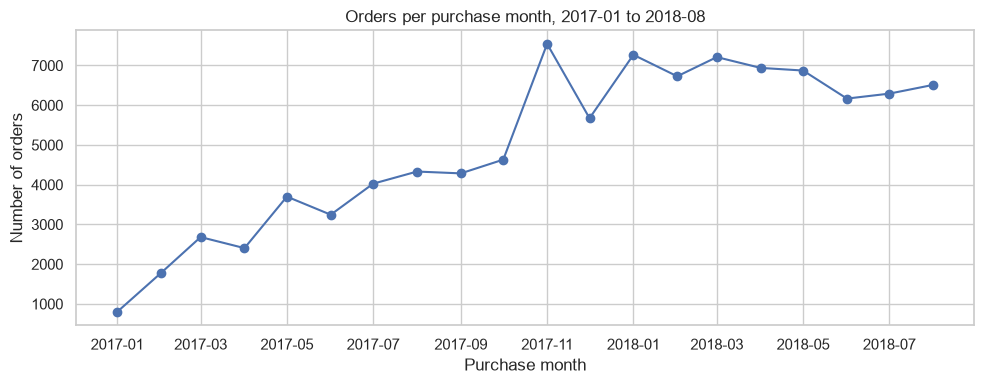

In [33]:
monthly_orders = order_summary.groupby("purchase_year_month").size()
trend_months = monthly_orders.loc["2017-01":"2018-08"]
left_out = monthly_orders.drop(trend_months.index)
print("Months left out of the trend:", left_out.to_dict())
print("Orders in the trend months:", int(trend_months.sum()), "of", int(monthly_orders.sum()))

jan_aug_2017 = monthly_orders.loc["2017-01":"2017-08"].sum()
jan_aug_2018 = monthly_orders.loc["2018-01":"2018-08"].sum()
yoy_growth_pct = (jan_aug_2018 / jan_aug_2017 - 1) * 100
peak_month, peak_orders = trend_months.idxmax(), int(trend_months.max())
print(f"January to August: 2017 = {jan_aug_2017}, 2018 = {jan_aug_2018}, change = {yoy_growth_pct:+.1f}%")
print(f"Busiest month: {peak_month} with {peak_orders} orders")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.to_datetime(trend_months.index), trend_months.values, marker="o")
ax.set_title("Orders per purchase month, 2017-01 to 2018-08")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Number of orders")
plt.tight_layout()
save_figure(fig, "q1_orders_per_month.png")
plt.show()

### Q2. Which product categories bring in the most item revenue?

| | |
|---|---|
| Metric | item revenue (sum of `price`) per category and its share of total |
| Columns and DataFrame | `category`, `price` in `valid_items` |
| Filters | orders with status other than `canceled` and `unavailable`. Products without a category are labeled `unknown` |
| Denominator for shares | total item revenue of `valid_items` |
| Method | `groupby` sum, sort, cumulative share |

Denominator (total item revenue): 13494400.74 | categories: 74


,item_revenue,items_sold,share_pct,cumulative_share_pct
category,,,,
health_beauty,1255695.13,9634,9.31,9.31
watches_gifts,1198185.21,5970,8.88,18.18
bed_bath_table,1035964.06,11097,7.68,25.86
sports_leisure,979740.92,8590,7.26,33.12
computers_accessories,904322.02,7781,6.70,39.82
furniture_decor,727465.05,8298,5.39,45.21
housewares,626825.80,6915,4.65,49.86
cool_stuff,620770.49,3779,4.60,54.46
auto,586585.73,4204,4.35,58.81


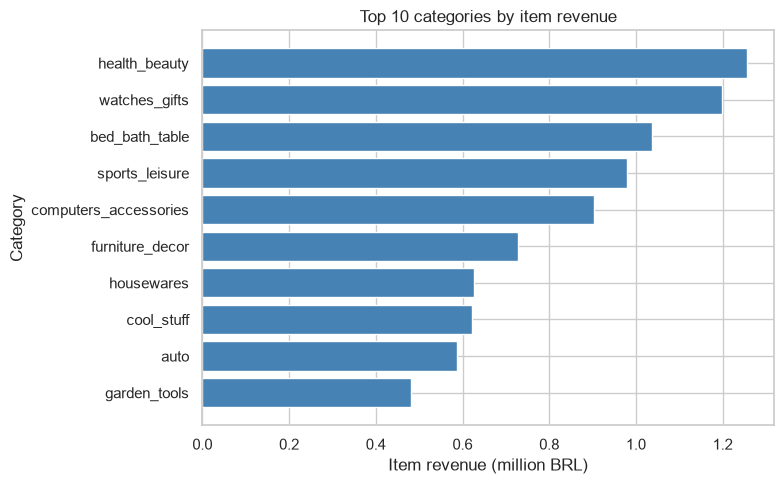

In [34]:
category_revenue = (
    valid_items.groupby("category")
    .agg(item_revenue=("price", "sum"), items_sold=("price", "size"))
    .sort_values("item_revenue", ascending=False)
)
total_item_revenue = category_revenue["item_revenue"].sum()
category_revenue["share_pct"] = category_revenue["item_revenue"] / total_item_revenue * 100
category_revenue["cumulative_share_pct"] = category_revenue["share_pct"].cumsum()
print("Denominator (total item revenue):", round(total_item_revenue, 2), "| categories:", len(category_revenue))
display(category_revenue.head(10).round(2))

top_categories_revenue = category_revenue.head(10).sort_values("item_revenue")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_categories_revenue.index, top_categories_revenue["item_revenue"] / 1e6, color="steelblue")
ax.set_title("Top 10 categories by item revenue")
ax.set_xlabel("Item revenue (million BRL)")
ax.set_ylabel("Category")
plt.tight_layout()
save_figure(fig, "q2_category_revenue.png")
plt.show()

### Q3. Which states have the most orders and customers?

| | |
|---|---|
| Metric | orders and distinct customers (`customer_unique_id`) per customer state, and each state's share of all orders |
| Columns and DataFrame | `customer_state`, `order_id`, `customer_unique_id` in `order_summary` |
| Filters | all order statuses |
| Denominator for shares | all orders (the number of rows in `order_summary`) |
| Method | `groupby` with `nunique` |

Denominator (all orders): 99441


,orders,customers,order_share_pct
customer_state,,,
SP,41746,40302,41.98
RJ,12852,12384,12.92
MG,11635,11259,11.70
RS,5466,5277,5.50
PR,5045,4882,5.07
SC,3637,3534,3.66
BA,3380,3277,3.40
DF,2140,2075,2.15
ES,2033,1964,2.04


Top 3 states together: 66.6% of orders


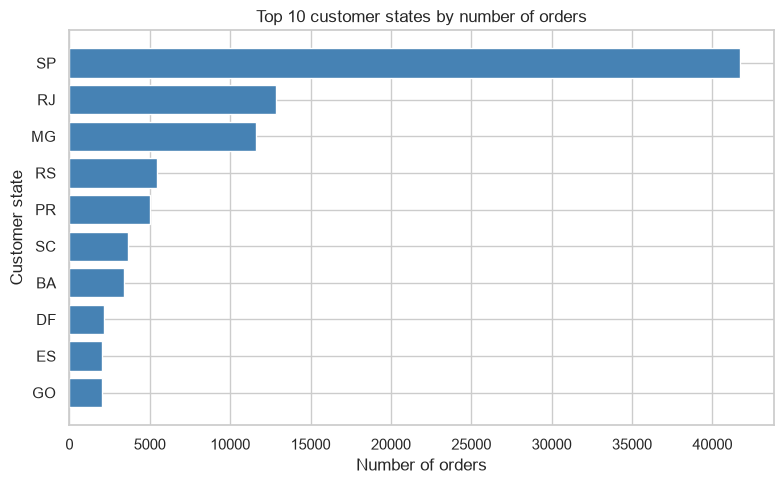

In [35]:
state_summary = (
    order_summary.groupby("customer_state")
    .agg(orders=("order_id", "nunique"), customers=("customer_unique_id", "nunique"))
    .sort_values("orders", ascending=False)
)
state_summary["order_share_pct"] = state_summary["orders"] / len(order_summary) * 100
print("Denominator (all orders):", len(order_summary))
display(state_summary.head(10).round(2))
top3_states_share = state_summary["order_share_pct"].head(3).sum()
print(f"Top 3 states together: {top3_states_share:.1f}% of orders")

top_states = state_summary.head(10).sort_values("orders")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_states.index, top_states["orders"], color="steelblue")
ax.set_title("Top 10 customer states by number of orders")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Customer state")
plt.tight_layout()
save_figure(fig, "q3_orders_by_state.png")
plt.show()

### Q4. What share of delivered orders arrived after the estimated date, and where?

| | |
|---|---|
| Metric | percentage of orders with `delay_days > 0` |
| Columns and DataFrame | `delay_days`, `is_late`, `customer_state` in `order_summary` |
| Filters | `order_status == "delivered"` and a recorded delivery date (the only rows where `delay_days` exists) |
| Denominator | delivered orders with a delivery date |
| Method | mean of `is_late`, then the same by state. States with fewer than 500 such orders are left out of the state ranking because their percentages are unstable |

Denominator: 96470 delivered orders with a delivery date
Late (calendar date): 6534 = 6.77%   (full-timestamp comparison would give 8.11%)
Median delay: -12 days (negative = earlier than estimated). Late orders average 10.6 days late


,delivered_orders,late_pct
customer_state,,
PA,946,11.21
RJ,12350,12.11
BA,3256,12.16
CE,1279,13.76
MA,717,17.43


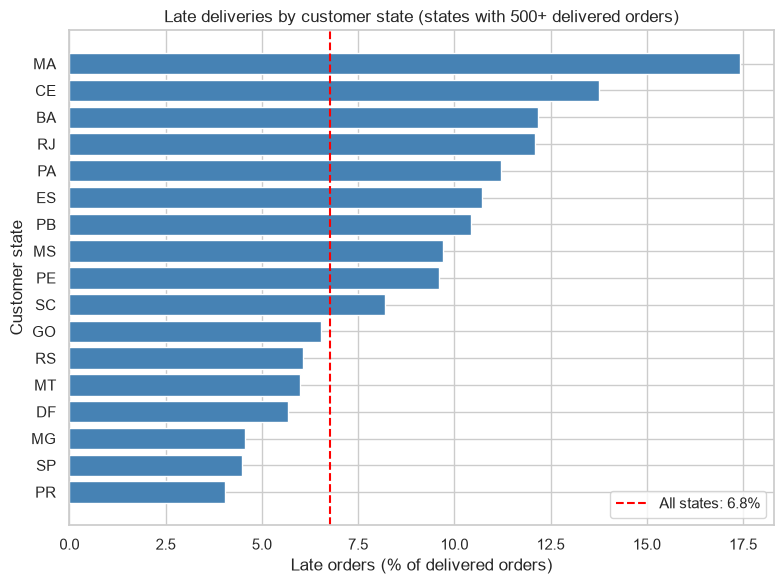

In [36]:
delivered = order_summary[order_summary["delay_days"].notna()].copy()
delivered["is_late"] = delivered["is_late"].astype(bool)
n_delivered = len(delivered)
n_late = int(delivered["is_late"].sum())
late_pct = n_late / n_delivered * 100
late_by_timestamp_pct = (delivered["order_delivered_customer_date"] > delivered["order_estimated_delivery_date"]).mean() * 100
median_delay = float(delivered["delay_days"].median())
mean_days_late = float(delivered.loc[delivered["is_late"], "delay_days"].mean())
print(f"Denominator: {n_delivered} delivered orders with a delivery date")
print(f"Late (calendar date): {n_late} = {late_pct:.2f}%   (full-timestamp comparison would give {late_by_timestamp_pct:.2f}%)")
print(f"Median delay: {median_delay:.0f} days (negative = earlier than estimated). Late orders average {mean_days_late:.1f} days late")

late_by_state = (
    delivered.groupby("customer_state")
    .agg(delivered_orders=("order_id", "size"), late_pct=("is_late", lambda s: s.mean() * 100))
    .query("delivered_orders >= 500")
    .sort_values("late_pct")
)
display(late_by_state.tail(5).round(2))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(late_by_state.index, late_by_state["late_pct"], color="steelblue")
ax.axvline(late_pct, color="red", linestyle="--", label=f"All states: {late_pct:.1f}%")
ax.set_title("Late deliveries by customer state (states with 500+ delivered orders)")
ax.set_xlabel("Late orders (% of delivered orders)")
ax.set_ylabel("Customer state")
ax.legend()
plt.tight_layout()
save_figure(fig, "q4_late_by_state.png")
plt.show()

### Q5. How do review scores differ by delivery performance?

| | |
|---|---|
| Metric | mean review score and share of 1 or 2 star reviews per delivery group |
| Groups | on time or early (`delay_days <= 0`), 1 to 7 days late, more than 7 days late |
| Columns and DataFrame | `delay_days`, `review_score` in `delivered` (one review per order, the latest) |
| Filters | delivered orders with a delivery date and a review |
| Method | `pd.cut` into groups, then `groupby` mean |

This shows an association only. A low score after a late delivery does not prove the delay caused it.

Denominator: 95824 delivered orders with a review (of 96470 delivered)


,orders,mean_score,low_score_pct
delivery_group,,,
on time or early,89443,4.29,9.27
1 to 7 days late,3600,2.71,49.39
more than 7 days late,2781,1.70,79.29


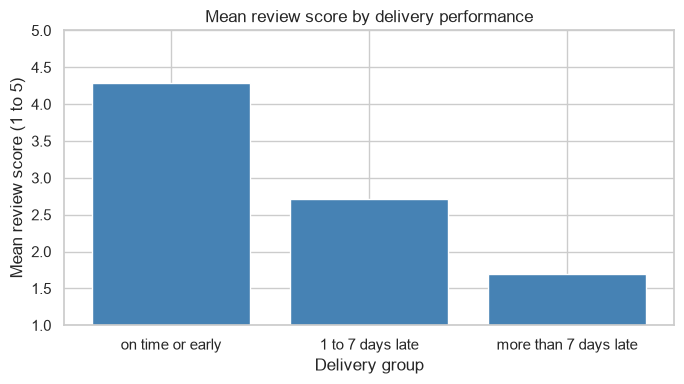

In [37]:
reviewed = delivered.dropna(subset=["review_score"]).copy()
reviewed["delivery_group"] = pd.cut(
    reviewed["delay_days"].astype(float), bins=[-np.inf, 0, 7, np.inf],
    labels=["on time or early", "1 to 7 days late", "more than 7 days late"],
)
score_by_group = (
    reviewed.groupby("delivery_group", observed=True)
    .agg(orders=("order_id", "size"), mean_score=("review_score", "mean"),
         low_score_pct=("review_score", lambda s: (s <= 2).mean() * 100))
)
print(f"Denominator: {len(reviewed)} delivered orders with a review (of {n_delivered} delivered)")
display(score_by_group.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(score_by_group.index.astype(str), score_by_group["mean_score"], color="steelblue")
ax.set_ylim(1, 5)
ax.set_title("Mean review score by delivery performance")
ax.set_xlabel("Delivery group")
ax.set_ylabel("Mean review score (1 to 5)")
plt.tight_layout()
save_figure(fig, "q5_review_by_delivery.png")
plt.show()

### Q6. Which payment methods are used most, by number and by value?

| | |
|---|---|
| Metric | payment records, distinct orders and payment value per payment type |
| Columns and DataFrame | `payment_type`, `payment_value` in `payments` joined to `valid_orders` |
| Filters | orders with status other than `canceled` and `unavailable` |
| Denominators | total payment records for record share, total payment value for value share. One order can use several types, so order counts do not add up to the total |
| Method | `groupby` with `nunique`, `sum` |

Denominators: records = 102573 | value = 15739137.01


,records,orders,total_value,avg_installments,record_share_pct,value_share_pct
payment_type,,,,,,
credit_card,75905,75618,12350042.56,3.51,74.00,78.47
boleto,19539,19539,2826802.30,1.00,19.05,17.96
voucher,5613,3745,349874.40,1.00,5.47,2.22
debit_card,1516,1515,212417.75,1.00,1.48,1.35


Orders paid with more than one payment type: 2.25% of 98206 orders with payments


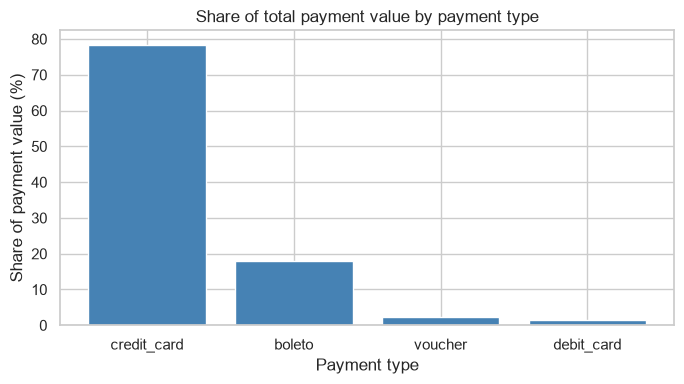

In [38]:
valid_payments = cleaned["payments"].merge(valid_orders[["order_id"]], on="order_id", how="inner")
payment_summary = (
    valid_payments.groupby("payment_type")
    .agg(records=("payment_sequential", "size"), orders=("order_id", "nunique"), total_value=("payment_value", "sum"),
         avg_installments=("payment_installments", "mean"))
    .sort_values("total_value", ascending=False)
)
payment_summary["record_share_pct"] = payment_summary["records"] / payment_summary["records"].sum() * 100
payment_summary["value_share_pct"] = payment_summary["total_value"] / payment_summary["total_value"].sum() * 100
print("Denominators: records =", len(valid_payments), "| value =", round(valid_payments["payment_value"].sum(), 2))
display(payment_summary.round(2))

types_per_order = valid_payments.groupby("order_id")["payment_type"].nunique()
multi_type_pct = (types_per_order > 1).mean() * 100
print(f"Orders paid with more than one payment type: {multi_type_pct:.2f}% of {len(types_per_order)} orders with payments")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(payment_summary.index, payment_summary["value_share_pct"], color="steelblue")
ax.set_title("Share of total payment value by payment type")
ax.set_xlabel("Payment type")
ax.set_ylabel("Share of payment value (%)")
plt.tight_layout()
save_figure(fig, "q6_payment_value_share.png")
plt.show()

### Q7. How heavy is freight compared with item price across states?

| | |
|---|---|
| Metric | freight as a percentage of item price (`sum(freight_value) / sum(price)`) and average freight per item, by customer state |
| Columns and DataFrame | `freight_value`, `price`, `customer_state` in `valid_items` |
| Filters | orders with status other than `canceled` and `unavailable`. States with fewer than 500 items are left out |
| Method | `groupby` sums, then ratio |

Overall freight as % of item price: 16.61%


,items,item_revenue,freight,avg_freight_per_item,freight_pct_of_price
customer_state,,,,,
SP,47153,5163867.22,714264.84,15.15,13.83
MS,818,116754.65,19121.04,23.38,16.38
DF,2397,300886.45,50440.76,21.04,16.76
RN,529,83034.98,18860.10,35.65,22.71
PI,539,86660.09,21105.38,39.16,24.35
MA,820,119291.62,31396.34,38.29,26.32


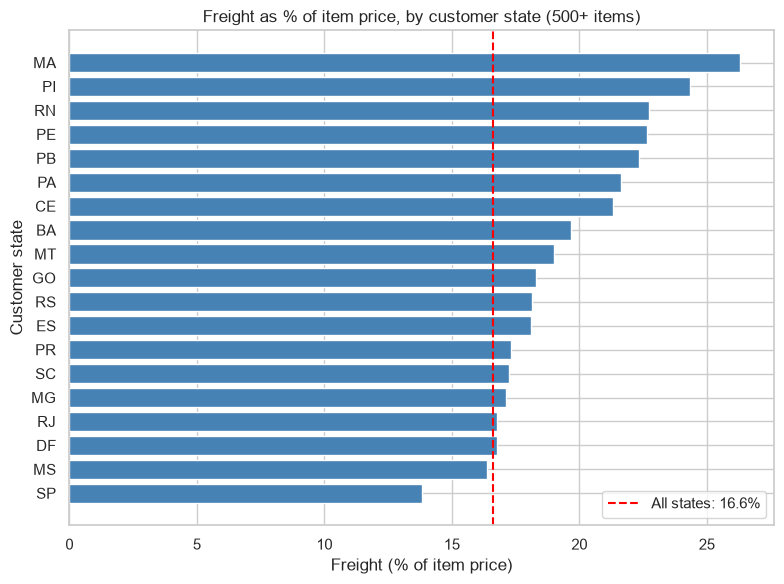

In [39]:
freight_by_state = (
    valid_items.groupby("customer_state")
    .agg(items=("price", "size"), item_revenue=("price", "sum"), freight=("freight_value", "sum"),
         avg_freight_per_item=("freight_value", "mean"))
    .query("items >= 500")
)
freight_by_state["freight_pct_of_price"] = freight_by_state["freight"] / freight_by_state["item_revenue"] * 100
freight_by_state = freight_by_state.sort_values("freight_pct_of_price")
overall_freight_pct = valid_items["freight_value"].sum() / valid_items["price"].sum() * 100
print(f"Overall freight as % of item price: {overall_freight_pct:.2f}%")
display(freight_by_state.iloc[[0, 1, 2, -3, -2, -1]].round(2))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(freight_by_state.index, freight_by_state["freight_pct_of_price"], color="steelblue")
ax.axvline(overall_freight_pct, color="red", linestyle="--", label=f"All states: {overall_freight_pct:.1f}%")
ax.set_title("Freight as % of item price, by customer state (500+ items)")
ax.set_xlabel("Freight (% of item price)")
ax.set_ylabel("Customer state")
ax.legend()
plt.tight_layout()
save_figure(fig, "q7_freight_share_by_state.png")
plt.show()

## K. Insights

Every number below is calculated from the results above when the cell runs. The limitation of each insight is written next to it.

In [40]:
top_category = category_revenue.index[0]
low_state, high_state = freight_by_state.index[0], freight_by_state.index[-1]
on_time_score = score_by_group.loc["on time or early", "mean_score"]
very_late_score = score_by_group.loc["more than 7 days late", "mean_score"]
card_share = payment_summary.loc["credit_card", "value_share_pct"]
card_installments = payment_summary.loc["credit_card", "avg_installments"]

insights = [
    (
        "Order volume grew strongly between 2017 and 2018.",
        f"Orders from January to August rose from {jan_aug_2017:,} in 2017 to {jan_aug_2018:,} in 2018 ({yoy_growth_pct:+.1f}%). "
        f"The busiest month was {peak_month} with {peak_orders:,} orders.",
        "It shows the platform was scaling quickly, which matters for planning capacity.",
        "Only about two years of data. The cause of the peak month is not tested, so no explanation is claimed.",
    ),
    (
        f"Item revenue is concentrated in a few categories, led by {top_category}.",
        f"{top_category} brings {category_revenue['share_pct'].iloc[0]:.1f}% of item revenue. "
        f"The top 5 categories bring {category_revenue['cumulative_share_pct'].iloc[4]:.1f}% and the top 10 bring "
        f"{category_revenue['cumulative_share_pct'].iloc[9]:.1f}% (out of {len(category_revenue)} categories).",
        "A small set of categories drives most sales, so assortment and marketing decisions there matter most.",
        "Revenue is item price only, without freight, and excludes canceled and unavailable orders. "
        "Items without a category form an 'unknown' group.",
    ),
    (
        f"Customers are concentrated in a few states, with {state_summary.index[0]} first.",
        f"{state_summary.index[0]} accounts for {state_summary['order_share_pct'].iloc[0]:.1f}% of orders "
        f"({state_summary['orders'].iloc[0]:,}). The top 3 states together account for {top3_states_share:.1f}%.",
        "Sales and logistics depend heavily on one region.",
        "Counts show where customers live, not how much each customer spends. State comes from the customer record.",
    ),
    (
        "Most delivered orders arrive before the estimated date, but a minority are late.",
        f"{late_pct:.2f}% of {n_delivered:,} delivered orders arrived after the estimated date. "
        f"The median order arrived {abs(median_delay):.0f} days before the estimate. Late orders were late by {mean_days_late:.1f} days on average. "
        f"Late share by state ranges up to {late_by_state['late_pct'].max():.1f}% ({late_by_state['late_pct'].idxmax()}).",
        "The estimate is conservative overall, but lateness is not equal across states.",
        f"Based on calendar-date comparison. Comparing full timestamps would give {late_by_timestamp_pct:.2f}%. "
        "Orders without a delivery date are not counted.",
    ),
    (
        "Late deliveries go together with lower review scores.",
        f"Mean review score is {on_time_score:.2f} for orders on time or early and {very_late_score:.2f} for orders more than 7 days late. "
        f"The share of 1 or 2 star reviews is {score_by_group.loc['on time or early', 'low_score_pct']:.1f}% versus "
        f"{score_by_group.loc['more than 7 days late', 'low_score_pct']:.1f}%.",
        "Delivery performance is linked to customer satisfaction, so reducing late deliveries is a reasonable goal.",
        "This is an association, not proof that lateness caused the score. Only delivered orders with a review are used.",
    ),
    (
        f"Freight weighs more on customers in {high_state} than in {low_state}.",
        f"Freight is {freight_by_state['freight_pct_of_price'].iloc[-1]:.1f}% of item price in {high_state} versus "
        f"{freight_by_state['freight_pct_of_price'].iloc[0]:.1f}% in {low_state} (all states: {overall_freight_pct:.1f}%).",
        "Shipping cost varies a lot by destination, which can affect how attractive orders are for far-away customers.",
        "Freight depends on product weight and size as well as distance, and this comparison does not control for them.",
    ),
    (
        "Credit cards carry most of the payment value.",
        f"Credit cards account for {card_share:.1f}% of payment value, with {card_installments:.1f} installments on average per card payment. "
        f"{multi_type_pct:.1f}% of orders with payments used more than one payment type.",
        "Card payments, often split into installments, carry most of the money, so card and installment handling matters for the business.",
        "Payment value includes vouchers and may include installment interest, so it is not identical to item revenue. "
        "Canceled and unavailable orders are excluded.",
    ),
]

for number, (finding, evidence, why, limitation) in enumerate(insights, start=1):
    print(f"Insight {number}: {finding}")
    print(f"  Evidence:   {evidence}")
    print(f"  Why it matters: {why}")
    print(f"  Limitation: {limitation}")
    print()

Insight 1: Order volume grew strongly between 2017 and 2018.
  Evidence:   Orders from January to August rose from 22,968 in 2017 to 53,991 in 2018 (+135.1%). The busiest month was 2017-11 with 7,544 orders.
  Why it matters: It shows the platform was scaling quickly, which matters for planning capacity.
  Limitation: Only about two years of data. The cause of the peak month is not tested, so no explanation is claimed.

Insight 2: Item revenue is concentrated in a few categories, led by health_beauty.
  Evidence:   health_beauty brings 9.3% of item revenue. The top 5 categories bring 39.8% and the top 10 bring 62.4% (out of 74 categories).
  Why it matters: A small set of categories drives most sales, so assortment and marketing decisions there matter most.
  Limitation: Revenue is item price only, without freight, and excludes canceled and unavailable orders. Items without a category form an 'unknown' group.

Insight 3: Customers are concentrated in a few states, with SP first.
  Evid